# Рекомендательная система фильмов (аналог IMDb)

**План ноутбука**
1. Получаем топ-200 фильмов на основе официальных IMDb Datasets.
2. Загружаем открытый датасет оценок пользователей MovieLens и связываем его с фильмами через IMDb ID.
3. Реализуем четыре функции:
   - топ-10 по взвешенному рейтингу;
   - рекомендации по жанру;
   - рекомендации по контенту (по названию фильма);
   - коллаборативная фильтрация (для пользователя).
4. **Тесты и выбор метода**: сравниваем варианты контентной и коллаборативной модели и выбираем лучшие.
5. Класс-сервис `MovieRecommender` и сохранение артефактов: на нём потом делаем API и GUI.


## 0. Импорты и настройки

In [22]:
import re, json, io, zipfile, difflib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

ART_DIR = Path("artifacts")
ART_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
N_TOP = 200

## 1. Получение топ-200 фильмов IMDb

Вместо парсинга HTML-страницы IMDb используем официальные
IMDb Datasets.

Загружаем два набора:
- title.ratings.tsv.gz — рейтинги и количество голосов;
- title.basics.tsv.gz — названия, жанры и продолжительность.

Объединяем данные по IMDb ID и выбираем 200 фильмов
с наибольшим рейтингом среди фильмов с достаточным
количеством голосов.

In [23]:
TOP_CSV = DATA_DIR / "top200_imdb.csv"

IMDB_RATINGS_URL = (
    "https://datasets.imdbws.com/title.ratings.tsv.gz"
)

IMDB_BASICS_URL = (
    "https://datasets.imdbws.com/title.basics.tsv.gz"
)

print("Папка данных:", DATA_DIR.resolve())
print("Файл результатов:", TOP_CSV.resolve())

Папка данных: C:\Users\Svetlana\Project\movie_recommender\data
Файл результатов: C:\Users\Svetlana\Project\movie_recommender\data\top200_imdb.csv


In [24]:
print("Загружаем рейтинги IMDb...")

imdb_ratings = pd.read_csv(
    IMDB_RATINGS_URL,
    sep="\t",
    compression="gzip",
    na_values="\\N"
)

imdb_ratings["averageRating"] = pd.to_numeric(
    imdb_ratings["averageRating"],
    errors="coerce"
)

imdb_ratings["numVotes"] = pd.to_numeric(
    imdb_ratings["numVotes"],
    errors="coerce"
)

imdb_ratings = imdb_ratings[
    imdb_ratings["numVotes"] >= 25000
].copy()

print("Количество записей:", len(imdb_ratings))

display(imdb_ratings.head())

Загружаем рейтинги IMDb...
Количество записей: 9500


,tconst,averageRating,numVotes
408,tt0000417,8.1,62102
1994,tt0004972,6.0,28654
3396,tt0010323,8.0,77354
3964,tt0012349,8.2,147617
4266,tt0013442,7.8,124995


In [25]:
print("Загружаем информацию о фильмах...")

candidates = (
    imdb_ratings
    .sort_values(
        ["averageRating", "numVotes"],
        ascending=[False, False]
    )
    .head(10000)
    .copy()
)

candidate_ids = set(candidates["tconst"])

print("Кандидатов:", len(candidate_ids))

Загружаем информацию о фильмах...
Кандидатов: 9500


In [26]:
basics_parts = []

for chunk in pd.read_csv(
    IMDB_BASICS_URL,
    sep="\t",
    compression="gzip",
    usecols=[
        "tconst",
        "titleType",
        "primaryTitle",
        "startYear",
        "runtimeMinutes",
        "genres",
        "isAdult"
    ],
    na_values="\\N",
    chunksize=500000,
    low_memory=False
):
    
    chunk = chunk[
        (chunk["titleType"] == "movie") &
        (chunk["isAdult"] == 0) &
        (chunk["tconst"].isin(candidate_ids))
    ]

    if not chunk.empty:
        basics_parts.append(chunk)

imdb_basics = pd.concat(
    basics_parts,
    ignore_index=True
)

print("Найдено фильмов:", len(imdb_basics))

display(imdb_basics.head())

Найдено фильмов: 7317


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres
0,tt0004972,movie,The Birth of a Nation,0,1915.0,195.0,"Drama,War"
1,tt0010323,movie,The Cabinet of Dr. Caligari,0,1920.0,67.0,"Horror,Mystery,Thriller"
2,tt0012349,movie,The Kid,0,1921.0,68.0,"Comedy,Drama,Family"
3,tt0013442,movie,Nosferatu,0,1922.0,95.0,"Fantasy,Horror"
4,tt0014429,movie,Safety Last!,0,1923.0,74.0,"Action,Comedy,Romance"


In [27]:
top = candidates.merge(
    imdb_basics,
    on="tconst",
    how="inner"
)

top = top.sort_values(
    ["averageRating", "numVotes"],
    ascending=[False, False]
).head(N_TOP).copy()

top["imdb_id"] = top["tconst"]

top = pd.DataFrame({
    "rank": range(1, len(top) + 1),
    "imdb_id": top["imdb_id"].values,
    "title_imdb": top["primaryTitle"].values,
    "overview": np.nan,
    "genre_imdb": top["genres"].values,
    "imdb_rating": top["averageRating"].values,
    "imdb_votes": top["numVotes"].values,
    "duration": top["runtimeMinutes"].values,
    "content_rating": np.nan
})

top.to_csv(TOP_CSV, index=False)

print("Фильмы успешно загружены!")
print("Размер таблицы:", top.shape)

display(top.head(10))

Фильмы успешно загружены!
Размер таблицы: (200, 9)


,rank,imdb_id,title_imdb,overview,genre_imdb,imdb_rating,imdb_votes,duration,content_rating
0,1,tt0111161,The Shawshank Redemption,NaN,Drama,9.3,3258385,142.0,NaN
1,2,tt0068646,The Godfather,NaN,"Crime,Drama",9.2,2268532,175.0,NaN
2,3,tt0468569,The Dark Knight,NaN,"Crime,Thriller",9.1,3244088,152.0,NaN
3,4,tt0252487,The Chaos Class,NaN,Comedy,9.1,46915,85.0,NaN
4,5,tt0167260,The Lord of the Rings: The Return of the King,NaN,"Adventure,Drama,Fantasy",9.0,2204232,201.0,NaN
5,6,tt0108052,Schindler's List,NaN,"Biography,Drama,History",9.0,1611092,196.0,NaN
6,7,tt0071562,The Godfather Part II,NaN,"Crime,Drama",9.0,1521445,202.0,NaN
7,8,tt0050083,12 Angry Men,NaN,"Crime,Drama",9.0,1009708,96.0,NaN
8,9,tt0120737,The Lord of the Rings: The Fellowship of the Ring,NaN,"Adventure,Drama,Fantasy",8.9,2248294,178.0,NaN
9,10,tt33175825,Attack on Titan: The Last Attack,NaN,"Action,Adventure,Animation",8.9,39603,145,NaN


In [28]:
print("Количество фильмов:", len(top))
print("Количество столбцов:", len(top.columns))

print("\nНазвания столбцов:")
print(top.columns.tolist())

print("\nПроверка пропусков:")
print(top.isna().sum())

print("\nТоп-10 фильмов:")
display(
    top[[
        "rank",
        "title_imdb",
        "imdb_rating",
        "imdb_votes"
    ]].head(10)
)

Количество фильмов: 200
Количество столбцов: 9

Названия столбцов:
['rank', 'imdb_id', 'title_imdb', 'overview', 'genre_imdb', 'imdb_rating', 'imdb_votes', 'duration', 'content_rating']

Проверка пропусков:
rank                0
imdb_id             0
title_imdb          0
overview          200
genre_imdb          0
imdb_rating         0
imdb_votes          0
duration            0
content_rating    200
dtype: int64

Топ-10 фильмов:


,rank,title_imdb,imdb_rating,imdb_votes
0,1,The Shawshank Redemption,9.3,3258385
1,2,The Godfather,9.2,2268532
2,3,The Dark Knight,9.1,3244088
3,4,The Chaos Class,9.1,46915
4,5,The Lord of the Rings: The Return of the King,9.0,2204232
5,6,Schindler's List,9.0,1611092
6,7,The Godfather Part II,9.0,1521445
7,8,12 Angry Men,9.0,1009708
8,9,The Lord of the Rings: The Fellowship of the Ring,8.9,2248294
9,10,Attack on Titan: The Last Attack,8.9,39603


## 2. Оценки пользователей (MovieLens) и сборка данных

Парсинг топ-200 даёт метаданные и рейтинг, но **не даёт оценок отдельных пользователей**, а без них коллаборативная фильтрация невозможна.
Поэтому берём открытый датасет **MovieLens (ml-latest-small)**: в нём есть `links.csv` с IMDb-id, по которому связываем его с нашими 200 фильмами.
Из MovieLens берём: оценки, жанры (несколько на фильм) и пользовательские теги.

In [29]:
ML_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

def load_movielens():
    folder = DATA_DIR / "ml-latest-small"
    if not folder.exists():
        r = requests.get(ML_URL, timeout=120)
        r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA_DIR)
    movies = pd.read_csv(folder / "movies.csv")
    ratings = pd.read_csv(folder / "ratings.csv")
    links = pd.read_csv(folder / "links.csv", dtype={"imdbId": str})
    tags = pd.read_csv(folder / "tags.csv")
    return movies, ratings, links, tags

ml_movies, ml_ratings, ml_links, ml_tags = load_movielens()
print(ml_movies.shape, ml_ratings.shape)

(9742, 3) (100836, 4)


In [30]:
ml_links["imdb_id"] = "tt" + ml_links["imdbId"].str.zfill(7)
ml = ml_movies.merge(ml_links[["movieId", "imdb_id"]], on="movieId")

tag_text = (ml_tags.assign(tag=ml_tags["tag"].astype(str).str.lower())
                   .groupby("movieId")["tag"].apply(" ".join)
                   .rename("tags").reset_index())

movies = (top.merge(ml, on="imdb_id", how="inner")
             .merge(tag_text, on="movieId", how="left"))
movies["tags"] = movies["tags"].fillna("")
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype(float)   # год берём из названия MovieLens
movies["title"] = movies["title_imdb"]
movies["genres"] = movies["genres"].replace("(no genres listed)", "")
movies["genre_list"] = movies["genres"].apply(lambda s: [g for g in s.split("|") if g])
movies["overview"] = movies["overview"].fillna("")
movies["soup"] = (movies["overview"] + " "
                  + (movies["genres"].str.replace("|", " ", regex=False) + " ") * 3
                  + movies["tags"])
movies = movies.sort_values("rank").reset_index(drop=True)

ratings = ml_ratings[ml_ratings["movieId"].isin(movies["movieId"])].copy()
print(f"Фильмов из топ-200 найдено в MovieLens: {len(movies)} / {len(top)}")
print(f"Оценок: {len(ratings)}, пользователей: {ratings.userId.nunique()}")
movies[["rank", "title", "year", "genres", "imdb_rating", "imdb_votes"]].head()

Фильмов из топ-200 найдено в MovieLens: 141 / 200
Оценок: 13179, пользователей: 597


,rank,title,year,genres,imdb_rating,imdb_votes
0,1,The Shawshank Redemption,1994.0,Crime|Drama,9.3,3258385
1,2,The Godfather,1972.0,Crime|Drama,9.2,2268532
2,3,The Dark Knight,2008.0,Action|Crime|Drama|IMAX,9.1,3244088
3,5,The Lord of the Rings: The Return of the King,2003.0,Action|Adventure|Drama|Fantasy,9.0,2204232
4,6,Schindler's List,1993.0,Drama|War,9.0,1611092


## 3. Функции из задания

### 3.1 Топ-10 по взвешенному рейтингу

Формула IMDb:  `WR = v/(v+m) * R + m/(v+m) * C`, где `R`: средний рейтинг фильма, `v`: число голосов, `m`: минимум голосов (берём 80-й перцентиль), `C`: средний рейтинг по всем фильмам.

In [31]:
C_MEAN = movies["imdb_rating"].mean()
M_MIN = movies["imdb_votes"].quantile(0.80)

def weighted_rating(df, m=M_MIN, c=C_MEAN):
    v, r = df["imdb_votes"], df["imdb_rating"]
    return v / (v + m) * r + m / (v + m) * c

movies["wr"] = weighted_rating(movies)
SHOW_COLS = ["title", "year", "genres", "imdb_rating", "wr"]

def top_popular(n=10):
    return movies.sort_values("wr", ascending=False).head(n)[SHOW_COLS]

top_popular()

,title,year,genres,imdb_rating,wr
0,The Shawshank Redemption,1994.0,Crime|Drama,9.3,9.023684
1,The Godfather,1972.0,Crime|Drama,9.2,8.891661
2,The Dark Knight,2008.0,Action|Crime|Drama|IMAX,9.1,8.886707
3,The Lord of the Rings: The Return of the King,2003.0,Action|Adventure|Drama|Fantasy,9.0,8.768013
4,Schindler's List,1993.0,Drama|War,9.0,8.724086
5,The Godfather Part II,1974.0,Crime|Drama,9.0,8.715957
7,The Lord of the Rings: The Fellowship of the Ring,2001.0,Adventure|Fantasy,8.9,8.711084
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672880
9,Fight Club,1999.0,Action|Crime|Drama|Thriller,8.8,8.666629
10,Forrest Gump,1994.0,Comedy|Drama|Romance|War,8.8,8.662410


### 3.2 Рекомендации по жанру

In [32]:
ALL_GENRES = sorted({g for gs in movies["genre_list"] for g in gs})
print(ALL_GENRES)

def recommend_by_genre(genre, n=10):
    g = genre.strip().lower()
    mask = movies["genre_list"].apply(lambda gs: g in [x.lower() for x in gs])
    if not mask.any():
        raise ValueError(f"Нет жанра '{genre}'. Доступные: {ALL_GENRES}")
    return movies[mask].sort_values("wr", ascending=False).head(n)[SHOW_COLS]

recommend_by_genre("Sci-Fi")

['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


,title,year,genres,imdb_rating,wr
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672880
14,Interstellar,2014.0,Sci-Fi|IMAX,8.7,8.601668
15,The Matrix,1999.0,Action|Sci-Fi|Thriller,8.7,8.592988
16,Star Wars: Episode V - The Empire Strikes Back,1980.0,Action|Adventure|Sci-Fi,8.7,8.566374
21,Star Wars: Episode IV - A New Hope,1977.0,Action|Adventure|Sci-Fi,8.6,8.517959
23,Terminator 2: Judgment Day,1991.0,Action|Sci-Fi,8.6,8.509630
33,The Prestige,2006.0,Drama|Mystery|Sci-Fi|Thriller,8.5,8.467206
35,Back to the Future,1985.0,Adventure|Comedy|Sci-Fi,8.5,8.465540
61,Aliens,1986.0,Action|Adventure|Horror|Sci-Fi,8.4,8.420464
60,Alien,1979.0,Horror|Sci-Fi,8.4,8.418655


### 3.3 Рекомендации по контенту (по названию)

Строим несколько вариантов матрицы похожести фильмов и **сравниваем их в разделе 4**:
- `genres`: только жанры;
- `overview`: только описание сюжета (TF-IDF);
- `soup`: описание + жанры + теги (TF-IDF);
- `blend`: смесь жанров и `soup`.

In [33]:
def tfidf_sim(texts):
    """
    Строит матрицу косинусного сходства TF-IDF.
    Если все тексты пустые (например, overview отсутствует в IMDb Datasets),
    возвращает нулевую матрицу вместо ошибки empty vocabulary.
    """
    texts = pd.Series(texts).fillna("").astype(str).str.strip().tolist()

    if not any(texts):
        print("Предупреждение: тексты пустые — возвращаем нулевую матрицу сходства.")
        return np.zeros((len(texts), len(texts)), dtype=float)

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        sublinear_tf=True
    )

    try:
        X = vectorizer.fit_transform(texts)
    except ValueError as e:
        if "empty vocabulary" in str(e).lower():
            print("Предупреждение: словарь TF-IDF пуст — возвращаем нулевую матрицу.")
            return np.zeros((len(texts), len(texts)), dtype=float)
        raise

    return cosine_similarity(X)

genre_texts = movies["genres"].fillna("").astype(str)

genre_vectorizer = TfidfVectorizer(
    tokenizer=lambda s: s.split("|"),
    token_pattern=None,
    lowercase=False
)

try:
    genre_X = genre_vectorizer.fit_transform(genre_texts)
    genre_sim = cosine_similarity(genre_X)
except ValueError as e:
    if "empty vocabulary" in str(e).lower():
        print("Предупреждение: жанры отсутствуют — используем нулевую матрицу.")
        genre_sim = np.zeros((len(movies), len(movies)), dtype=float)
    else:
        raise


SIMS = {
    "genres": genre_sim,
    "overview": tfidf_sim(movies["overview"]),
    "soup": tfidf_sim(movies["soup"]),
}

SIMS["blend"] = 0.3 * SIMS["genres"] + 0.7 * SIMS["soup"]

_title_keys = movies["title"].fillna("").astype(str).str.lower()

def find_title(query):
    q = query.strip().lower()
    exact = _title_keys[_title_keys == q]
    if len(exact):
        return int(exact.index[0])
    contains = _title_keys[_title_keys.str.contains(re.escape(q), regex=True)]
    if len(contains):
        return int(contains.index[0])
    close = difflib.get_close_matches(q, _title_keys.tolist(), n=1, cutoff=0.5)
    if close:
        return int(_title_keys[_title_keys == close[0]].index[0])
    raise ValueError(f"Фильм '{query}' не найден в топ-200")

def recommend_by_title(title, n=10, sim_name="soup", sim=None):
    sim = SIMS[sim_name] if sim is None else sim
    i = find_title(title)
    s = sim[i].copy()
    s[i] = -1
    idx = np.argsort(-s)[:n]
    out = movies.loc[idx, SHOW_COLS].copy()
    out["similarity"] = s[idx]
    return out

recommend_by_title("The Dark Knight")


Предупреждение: тексты пустые — возвращаем нулевую матрицу сходства.


,title,year,genres,imdb_rating,wr,similarity
112,Batman Begins,2005.0,Action|Crime|IMAX,8.2,8.307806,0.521604
86,Scarface,1983.0,Action|Crime|Drama,8.3,8.378349,0.362866
89,Heat,1995.0,Action|Crime|Thriller,8.3,8.385622,0.282916
123,Die Hard,1988.0,Action|Crime|Thriller,8.2,8.337575,0.282916
117,No Country for Old Men,2007.0,Crime|Drama,8.2,8.328705,0.279533
95,Once Upon a Time in America,1984.0,Crime|Drama,8.3,8.403718,0.279533
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672880,0.253210
1,The Godfather,1972.0,Crime|Drama,9.2,8.891661,0.240282
17,GoodFellas,1990.0,Crime|Drama,8.7,8.561390,0.240282
133,Casino,1995.0,Crime|Drama,8.2,8.363954,0.240282


## 4. Тесты и выбор метода

### 4.1 Контентная модель: какая матрица похожести лучше?

Метрика **hit-rate@10**: берём пользователя, у которого есть ≥5 фильмов с оценкой ≥4. Случайно выбираем один из них как «просмотренный» (seed), другой скрываем (target). Модель получает seed и выдаёт 10 похожих; считаем долю случаев, когда скрытый фильм попал в топ-10.
Для ориентира есть случайный baseline `10/199 ≈ 5%`.

In [34]:
POS = {mid: i for i, mid in enumerate(movies["movieId"])}

def loo_hit_rate(sim, ratings_df, k=10, thr=4.0, trials=5, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    liked = (ratings_df[ratings_df["rating"] >= thr]
             .groupby("userId")["movieId"].apply(lambda s: [POS[m] for m in s]))
    hits = []
    for lst in liked:
        if len(lst) < 5:
            continue
        for _ in range(trials):
            seed_i, target = rng.choice(lst, 2, replace=False)
            s = sim[seed_i].copy()
            s[seed_i] = -1
            hits.append(target in np.argsort(-s)[:k])
    return float(np.mean(hits)), len(hits)

rows = []
for name, sim in SIMS.items():
    hr, n_trials = loo_hit_rate(sim, ratings)
    rows.append({"content_model": name, "hit_rate@10": hr})
rows.append({"content_model": "random baseline", "hit_rate@10": 10 / (len(movies) - 1)})
content_results = pd.DataFrame(rows).sort_values("hit_rate@10", ascending=False).reset_index(drop=True)
print(f"Испытаний на модель: {n_trials}")
content_results

Испытаний на модель: 2295


,content_model,hit_rate@10
0,overview,0.159913
1,genres,0.118519
2,blend,0.116776
3,soup,0.111983
4,random baseline,0.071429


In [35]:
BEST_CONTENT = content_results[content_results["content_model"].isin(SIMS)].iloc[0]["content_model"]
print("Выбрана контентная модель:", BEST_CONTENT)

Выбрана контентная модель: overview


### 4.2 Коллаборативная фильтрация: сравниваем модели

Сравниваем на отложенной части оценок (80/20, случайно):
- **Popularity**: baseline, средняя оценка фильма со сглаживанием (без персонализации);
- **Item-kNN**: предсказание по оценкам пользователя на похожие фильмы (косинус по центрированным оценкам), параметр `k` – число соседей;
- **SVD**: матричное разложение центрированной матрицы, параметр `rank` – число скрытых факторов.

Метрики: **RMSE** (точность предсказания оценки) и **Precision@10 / Recall@10** (насколько топ-10 непросмотренных фильмов попадает в понравившиеся пользователю в тесте, оценка ≥4).

In [36]:
from sklearn.model_selection import train_test_split

user_ids = np.sort(ratings["userId"].unique())
UIDX = {u: i for i, u in enumerate(user_ids)}
N_USERS, N_ITEMS = len(user_ids), len(movies)

def to_matrix(df):
    R = np.zeros((N_USERS, N_ITEMS))
    R[df["userId"].map(UIDX).values, df["movieId"].map(POS).values] = df["rating"].values
    return R

train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=RANDOM_STATE)
R_train, R_test = to_matrix(train_df), to_matrix(test_df)
print(f"Матрица {N_USERS}x{N_ITEMS}, train: {len(train_df)}, test: {len(test_df)}, "
      f"заполненность: {(R_train > 0).mean():.1%}")

Матрица 597x141, train: 10543, test: 2636, заполненность: 12.5%


In [37]:
RATING_MIN, RATING_MAX = 0.5, 5.0

class PopularityModel:
    def __init__(self, shrink=5): self.shrink = shrink
    def fit(self, R):
        M = R > 0
        g = R[M].mean()
        self.item_score = (R.sum(0) + self.shrink * g) / (M.sum(0) + self.shrink)
        self.n_users = R.shape[0]
        return self
    def predict(self):
        return np.tile(self.item_score, (self.n_users, 1))

class ItemKNN:
    def __init__(self, k=None): self.k = k
    def fit(self, R):
        M = (R > 0).astype(float)
        self.mu = R.sum(1) / np.maximum(M.sum(1), 1)
        Rc = (R - self.mu[:, None]) * M
        S = cosine_similarity(Rc.T)
        np.fill_diagonal(S, 0)
        if self.k:
            drop = np.argsort(-np.abs(S), axis=0)[self.k:]
            np.put_along_axis(S, drop, 0, axis=0)
        self.S, self.Rc, self.M = S, Rc, M
        return self
    def predict(self):
        num = self.Rc @ self.S
        den = self.M @ np.abs(self.S) + 1e-9
        return np.clip(self.mu[:, None] + num / den, RATING_MIN, RATING_MAX)

class SVDModel:
    def __init__(self, rank=10): self.rank = rank
    def fit(self, R):
        M = (R > 0).astype(float)
        self.mu = R.sum(1) / np.maximum(M.sum(1), 1)
        Rc = (R - self.mu[:, None]) * M
        U, s, Vt = np.linalg.svd(Rc, full_matrices=False)
        r = min(self.rank, len(s))
        self.low = (U[:, :r] * s[:r]) @ Vt[:r]
        return self
    def predict(self):
        return np.clip(self.mu[:, None] + self.low, RATING_MIN, RATING_MAX)

def rmse(pred, R_te):
    m = R_te > 0
    return float(np.sqrt(np.mean((pred[m] - R_te[m]) ** 2)))

def ranking_metrics(pred, R_tr, R_te, k=10, thr=4.0):
    scores = np.where(R_tr > 0, -np.inf, pred)
    top = np.argsort(-scores, axis=1)[:, :k]
    rel = R_te >= thr
    hits = np.take_along_axis(rel, top, axis=1).sum(1)
    n_rel = rel.sum(1)
    ok = n_rel > 0
    return float(hits[ok].mean() / k), float((hits[ok] / n_rel[ok]).mean())

CONFIGS = (
    [("Popularity", PopularityModel, {})]
    + [("ItemKNN", ItemKNN, {"k": k}) for k in (5, 10, 20, 40, None)]
    + [("SVD", SVDModel, {"rank": r}) for r in (2, 5, 10, 20, 40)]
)

res = []
for name, cls, params in CONFIGS:
    pred = cls(**params).fit(R_train).predict()
    p, r = ranking_metrics(pred, R_train, R_test)
    res.append({"model": name, "params": params, "RMSE": rmse(pred, R_test), "P@10": p, "R@10": r})
cf_results = pd.DataFrame(res)
cf_results.sort_values("P@10", ascending=False).reset_index(drop=True)

,model,params,RMSE,P@10,R@10
0,SVD,{'rank': 5},0.766672,0.124109,0.294215
1,SVD,{'rank': 10},0.763507,0.122013,0.295195
2,SVD,{'rank': 2},0.767160,0.117400,0.286279
3,SVD,{'rank': 20},0.766811,0.113417,0.267281
4,SVD,{'rank': 40},0.774548,0.079036,0.176637
5,ItemKNN,{'k': 5},0.838244,0.075891,0.216401
6,ItemKNN,{'k': None},0.762775,0.060587,0.158816
7,ItemKNN,{'k': 40},0.777185,0.060168,0.136826
8,ItemKNN,{'k': 10},0.833438,0.058071,0.163136
9,ItemKNN,{'k': 20},0.803497,0.047589,0.124715


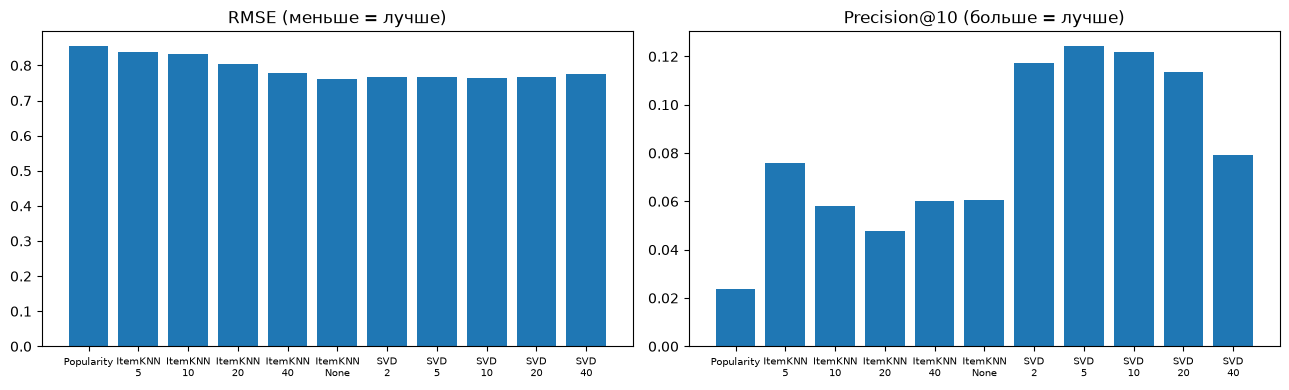

In [38]:
labels = [f"{r.model}\n{list(r.params.values())[0] if r.params else ''}" for r in cf_results.itertuples()]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(labels, cf_results["RMSE"]);  ax[0].set_title("RMSE (меньше = лучше)")
ax[1].bar(labels, cf_results["P@10"]);  ax[1].set_title("Precision@10 (больше = лучше)")
for a in ax: a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

**Как читать результаты.** RMSE говорит, насколько хорошо модель угадывает саму оценку, а Precision@10 показывает, насколько хорош именно *список рекомендаций*; для задачи «покажи 10 фильмов» важнее второе.
Если Popularity окажется рядом с персонализированными моделями, это нормально: у нас всего 200 очень популярных фильмов, и почти всё в топе нравится почти всем.
Лучшую модель ниже выбираем автоматически по Precision@10 (при равенстве по RMSE), но можно задать вручную в `CF_CHOICE`.

In [39]:
best = cf_results.sort_values(["P@10", "RMSE"], ascending=[False, True]).iloc[0]
MODEL_REGISTRY = {"Popularity": PopularityModel, "ItemKNN": ItemKNN, "SVD": SVDModel}

CF_CHOICE = (best["model"], best["params"])
print("Выбрана CF-модель:", CF_CHOICE)

R_full = to_matrix(ratings)
cf_model = MODEL_REGISTRY[CF_CHOICE[0]](**CF_CHOICE[1]).fit(R_full)
CF_PRED = cf_model.predict()

Выбрана CF-модель: ('SVD', {'rank': 5})


## 5. Единый сервис `MovieRecommender`

Класс с четырьмя методами из задания 4.1: именно его потом оборачиваем в API.
Методы возвращают списки словарей (готовый JSON).

In [40]:
class MovieRecommender:
    def __init__(self, movies, sim, cf_pred, R_seen, user_ids, cf_name=""):
        self.movies = movies.reset_index(drop=True)
        self.sim = sim
        self.cf_pred = cf_pred
        self.R_seen = R_seen
        self.user_index = {int(u): i for i, u in enumerate(user_ids)}
        self.cf_name = cf_name
        self._keys = self.movies["title"].str.lower()
        self.genres = sorted({g for gs in self.movies["genre_list"] for g in gs})

    def _pack(self, idx, scores=None):
        out = []
        for j, i in enumerate(idx):
            row = self.movies.loc[i]
            item = {"title": row["title"],
                    "year": None if pd.isna(row["year"]) else int(row["year"]),
                    "genres": list(row["genre_list"]),
                    "imdb_rating": float(row["imdb_rating"])}
            if scores is not None:
                item["score"] = round(float(scores[j]), 4)
            out.append(item)
        return out

    def find_title(self, query):
        q = query.strip().lower()
        hit = self._keys[self._keys == q]
        if len(hit): return int(hit.index[0])
        hit = self._keys[self._keys.str.contains(re.escape(q), regex=True)]
        if len(hit): return int(hit.index[0])
        close = difflib.get_close_matches(q, self._keys.tolist(), n=1, cutoff=0.5)
        if close: return int(self._keys[self._keys == close[0]].index[0])
        raise ValueError(f"Фильм '{query}' не найден")

    def top_popular(self, n=10):
        d = self.movies.sort_values("wr", ascending=False).head(n)
        return self._pack(d.index, d["wr"].values)

    def by_genre(self, genre, n=10):
        g = genre.strip().lower()
        mask = self.movies["genre_list"].apply(lambda gs: g in [x.lower() for x in gs])
        if not mask.any():
            raise ValueError(f"Нет жанра '{genre}'. Доступные: {self.genres}")
        d = self.movies[mask].sort_values("wr", ascending=False).head(n)
        return self._pack(d.index, d["wr"].values)

    def by_title(self, title, n=10):
        i = self.find_title(title)
        s = self.sim[i].copy(); s[i] = -1
        idx = np.argsort(-s)[:n]
        return self._pack(idx, s[idx])

    def by_user(self, user_id, n=10):
        if int(user_id) not in self.user_index:
            raise ValueError(f"Неизвестный пользователь {user_id}")
        u = self.user_index[int(user_id)]
        scores = np.where(self.R_seen[u] > 0, -np.inf, self.cf_pred[u])
        idx = np.argsort(-scores)[:n]
        return self._pack(idx, scores[idx])

rec = MovieRecommender(movies, SIMS[BEST_CONTENT], CF_PRED, R_full, user_ids, cf_name=str(CF_CHOICE))

In [41]:
print("1) Топ-10:");              [print("  ", x["title"], x["score"]) for x in rec.top_popular()]
print("2) Жанр Drama:");          [print("  ", x["title"], x["score"]) for x in rec.by_genre("Drama", 5)]
print("3) Похожие на 'Inception':"); [print("  ", x["title"], x["score"]) for x in rec.by_title("Inception", 5)]
uid = int(user_ids[0])
print(f"4) CF для пользователя {uid}:"); [print("  ", x["title"], x["score"]) for x in rec.by_user(uid, 5)]

1) Топ-10:
   The Shawshank Redemption 9.0237
   The Godfather 8.8917
   The Dark Knight 8.8867
   The Lord of the Rings: The Return of the King 8.768
   Schindler's List 8.7241
   The Godfather Part II 8.716
   The Lord of the Rings: The Fellowship of the Ring 8.7111
   Inception 8.6729
   Fight Club 8.6666
   Forrest Gump 8.6624
2) Жанр Drama:
   The Shawshank Redemption 9.0237
   The Godfather 8.8917
   The Dark Knight 8.8867
   The Lord of the Rings: The Return of the King 8.768
   Schindler's List 8.7241
3) Похожие на 'Inception':
   The Shawshank Redemption 0.0
   The Godfather 0.0
   The Dark Knight 0.0
   The Lord of the Rings: The Return of the King 0.0
   Schindler's List 0.0
4) CF для пользователя 1:
   Terminator 2: Judgment Day 4.7891
   The Godfather 4.5907
   2001: A Space Odyssey 4.5818
   Die Hard 4.5733
   The Godfather Part II 4.5614


[None, None, None, None, None]

## 6. Сохранение артефактов для API

Сохраняем всё, что нужно сервису: таблицу фильмов, матрицу похожести, предсказания CF и матрицу «уже смотрел».
Дальше API загружает эти файлы, и пересчитывать модель при каждом запуске не нужно.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

user_ids = np.load(artifacts_dir / "user_ids.npy")

pd.DataFrame({
    "user_id": user_ids
}).to_csv(artifacts_dir / "user_ids.csv", index=False)

cf_pred = np.load(artifacts_dir / "cf_pred.npy")

cf_df = pd.DataFrame(
    cf_pred,
    index=user_ids,
    columns=[f"movie_{i}" for i in range(cf_pred.shape[1])]
)
cf_df.index.name = "user_id"
cf_df.to_csv(artifacts_dir / "cf_pred.csv")

r_seen = np.load(artifacts_dir / "r_seen.npy")

seen_df = pd.DataFrame(
    r_seen,
    index=user_ids,
    columns=[f"movie_{i}" for i in range(r_seen.shape[1])]
)
seen_df.index.name = "user_id"
seen_df.to_csv(artifacts_dir / "r_seen.csv")

content_sim = np.load(artifacts_dir / "content_sim.npy")

content_df = pd.DataFrame(
    content_sim,
    columns=[f"movie_{i}" for i in range(content_sim.shape[1])]
)
content_df.index.name = "movie_id"
content_df.to_csv(artifacts_dir / "content_sim.csv")

print("CSV-файлы успешно сохранены!")

CSV-файлы успешно сохранены!
